# Test_Flight_MoS
Brings every piece together and flies the Method of Sections rocket.

| Notebook | Provides |
|---|---|
| `25_26_MoS_Parameters` | every number and data file |
| `Environment_IREC_Launch_Site` | `env` |
| `M2500T` | `M2500T` motor |
| `AFC_Controller` | `controller_function` (air-brake control law) |
| `Method_of_Sections` | `rocket`, `air_brakes` |

**To make a change:** edit and save the notebook it lives in, then re-run this notebook from the top. Everything is reloaded fresh each time, so no old values carry over.

All six notebooks must be in the same folder as `AeroTech_M2500T.eng`, `RASAeroII Cd Data.xlsx` and `airbrake_cd.xlsx`.

## Load the components
- **`%run`:** runs another notebook *in this namespace*, so every variable it defines (`env`, `M2500T`, `rocket`, ...) is available here.
- **Order matters:** the parameters come first because everything uses them, and the motor and controller come before the rocket because the rocket mounts the motor and hands the controller to the air brakes.
- **`PIPELINE = True`:** tells the component notebooks to skip their `.info()` printouts and plots, so only the flight results show here.

In [23]:
from rocketpy import Rocket, SolidMotor, Environment, Flight   # simulation classes
import numpy as np                                              # arrays and maths
import pandas as pd                                             # reading .xlsx data files
import datetime                                                 # launch date for the forecast
import matplotlib.pyplot as plt                                 # plotting

In [24]:
PIPELINE = True                           # component notebooks skip their info printouts/plots

%run 25_26_MoS_Parameters.ipynb
%run Environment_IREC_Launch_Site.ipynb
%run M2500T.ipynb
%run AFC_Controller.ipynb
%run Method_of_Sections.ipynb

# Quick check that everything loaded
print(f"Atmosphere: {ATMOSPHERE_MODEL} | Motor: M2500T | Liftoff mass: {rocket.total_mass(0):.3f} kg")

Atmosphere: Forecast | Motor: M2500T | Liftoff mass: 28.276 kg


## Flight
- **`rail_length`, `inclination`, `heading`:** the launch rail. Inclination is measured from horizontal and heading from north.
- **`time_overshoot=False`:** makes the solver stop exactly at every controller sample (10 Hz). That way the air-brake controller sees the true state and its commands take effect at the right moment. Setting it to `True` is faster but interpolates between steps, which is fine without a controller.
- **`terminate_on_apogee=True`:** stops the simulation at apogee. The ascent is all that's needed for apogee, stability and air-brake analysis. Set it to `False` to simulate the descent under parachute and get the drift distance.
- **`prints.*` / `plots.*`:** RocketPy's built-in summaries.

c:\Users\101163874\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: invalid value encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)



Burn out State

Burn out time: 4.264 s
Altitude at burn out: 1630.548 m (ASL) | 779.348 m (AGL)
Rocket speed at burn out: 301.461 m/s
Freestream velocity at burn out: 303.007 m/s
Mach Number at burn out: 0.886
Kinetic energy at burn out: 1.073e+06 J

Apogee State

Apogee Time: 23.931 s
Apogee Altitude: 3976.044 m (ASL) | 3124.844 m (AGL)
Apogee Freestream Speed: 33.124 m/s
Apogee X position: -299.310 m
Apogee Y position: -553.456 m
Apogee latitude: 31.9850235°
Apogee longitude: -102.0731730°


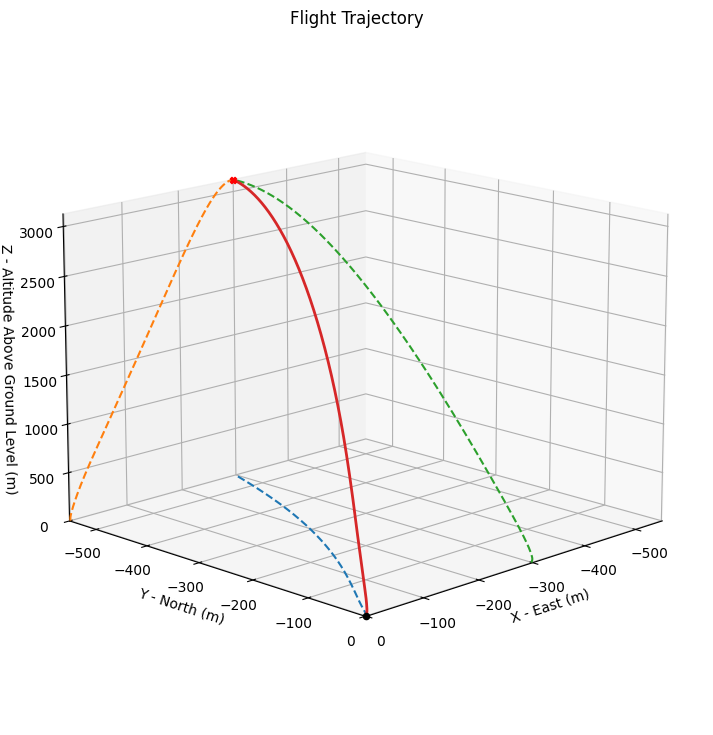

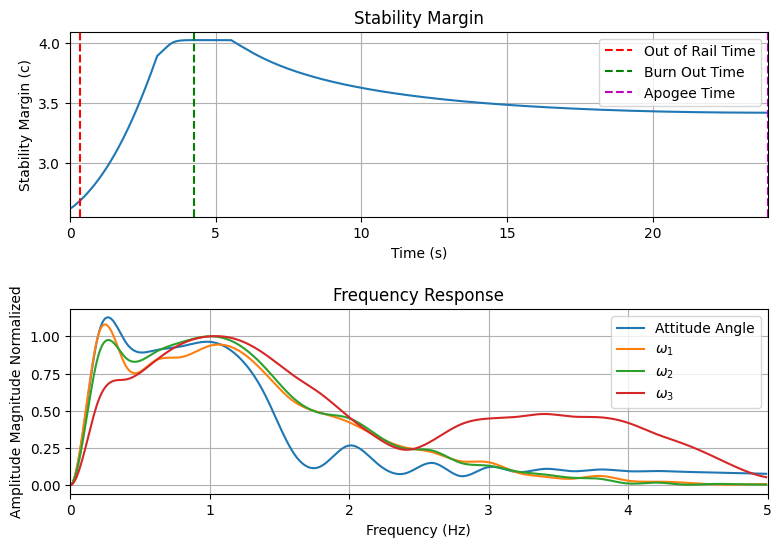

In [25]:
test_flight = Flight(
    rocket=rocket,                  # from Method_of_Sections
    environment=env,                # from Environment_IREC_Launch_Site
    rail_length=RAIL_LENGTH,        # m
    inclination=INCLINATION,        # deg from horizontal
    heading=HEADING,                # deg from north
    time_overshoot=False,           # step exactly on controller samples
    terminate_on_apogee=True,       # ascent only
    )

test_flight.prints.burn_out_conditions()       # altitude, speed and Mach at burnout
test_flight.prints.apogee_conditions()         # apogee altitude, time and position
test_flight.plots.trajectory_3d()              # 3D flight path
test_flight.plots.stability_and_control_data() # RocketPy's stability margin + frequency response

## Air-brake controller history
`get_controller_observed_variables()` returns everything `controller_function` returned, one `(time, deployment, Cd)` tuple per 10 Hz step. The loop splits it into three lists for plotting.

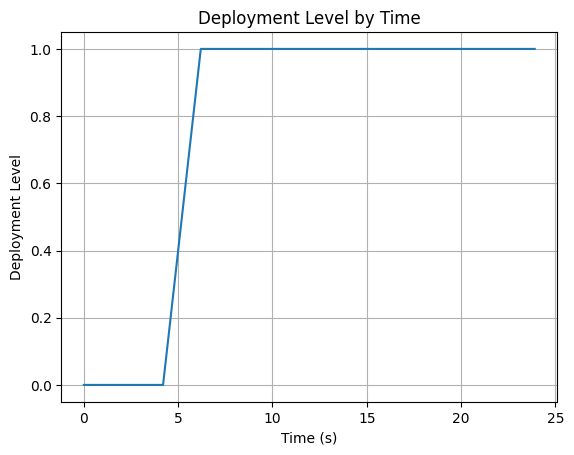

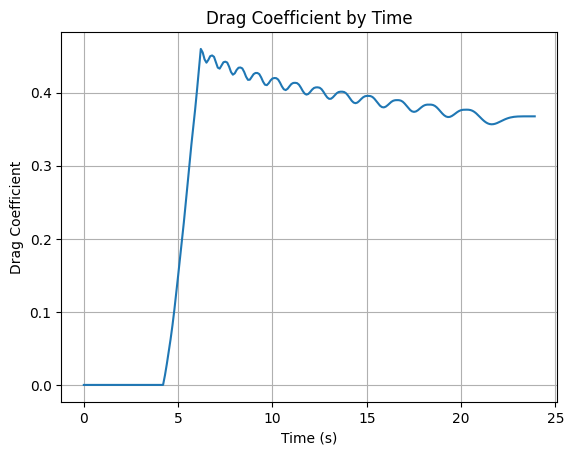

In [26]:
time_list, deployment_level_list, drag_coefficient_list = [], [], []

obs_vars = test_flight.get_controller_observed_variables()   # [(time, deployment, Cd), ...]

for time, deployment_level, drag_coefficient in obs_vars:
    time_list.append(time)
    deployment_level_list.append(deployment_level)
    drag_coefficient_list.append(drag_coefficient)

# Plot deployment level by time
plt.plot(time_list, deployment_level_list)
plt.xlabel("Time (s)")
plt.ylabel("Deployment Level")
plt.title("Deployment Level by Time")
plt.grid()
plt.show()

# Plot drag coefficient by time
plt.plot(time_list, drag_coefficient_list)
plt.xlabel("Time (s)")
plt.ylabel("Drag Coefficient")
plt.title("Drag Coefficient by Time")
plt.grid()
plt.show()